# Machine Learning Capstone Project (23CSE301) — Review 1
## Track 2: Classification Track (Part A) — Bank Marketing Term Deposit Subscription

### 1. Project Overview
- **Course**: 23CSE301 Machine Learning
- **Academic Year**: 2026–27
- **Submission Scope**: Review 1 (Classification Track — Part A)
- **Dataset**: Bank Marketing Dataset (`Data/classification/bank.csv`)
- **Target Variable**: `y` (binary: `'yes'` = subscribed to term deposit, `'no'` = did not subscribe)
- **Primary Tooling**: Python 3, scikit-learn, Pandas, NumPy, Matplotlib, Seaborn

This notebook delivers the end-to-end Machine Learning pipeline for the Bank Marketing classification challenge under the formal Review 1 specifications:
1. **Dataset Audit & Systematic EDA**: Systematic visualization covering **every single predictor feature** in the dataset (7 numerical features, 9 categorical features, and the target).
2. **Data Cleaning & Nuance Analysis**: Missing value and duplicate audits, evaluation of 'unknown' categories, and formal discussion of class imbalance.
3. **Operational Feature Limitation**: Critical documentation regarding the operational limitation of the call `duration` feature in prospective marketing campaigns.
4. **Stratified Splitting & Leakage-Free Preprocessing**: 80:20 train/test split strictly stratified on `y`, followed by dense one-hot encoding and scaling fitted exclusively on training data.
5. **Feature Engineering**: Domain-justified creation of `pdays_contacted` and `balance_negative` indicators with zero data leakage.
6. **Part-A Model Implementations**: Training, predictions, and diagnostic evaluation for all **five required Part-A classifiers**:
   - Logistic Regression (Baseline)
   - K-Nearest Neighbors Classifier
   - Gaussian Naive Bayes
   - Decision Tree Classifier
   - Support Vector Classifier (SVC)
7. **Comprehensive Evaluation & Confusion Matrices**: Reporting Accuracy, Positive-Class Precision, Positive-Class Recall, Weighted F1-score, ROC-AUC (using `decision_function` for SVC), and individual formatted confusion matrix heatmaps for all five models.
8. **Master Preliminary Comparison Table**: Consolidated comparison table sorted by **Weighted F1 descending** with analytical interpretation of class imbalance impacts.

### 2. Problem Definition
Direct marketing campaigns conducted by retail financial institutions represent substantial operational expenditure. Telemarketing campaigns incur direct labor costs and risk customer fatigue. Identifying prospective clients who are genuinely inclined to subscribe to long-term deposits allows financial institutions to prioritize outreach, allocate sales resources efficiently, and improve overall campaign conversion rates.

**Analytical Objective**:
Formulate a binary classification problem to predict whether a prospective client will subscribe to a bank term deposit ($y \in \{\text{'no'}, \text{'yes'}\}$) based on:
- Client demographic attributes (age, job, marital status, education, credit default, bank balance, housing loan, personal loan).
- Current campaign contact details (contact communication type, last contact day of month, last contact month, call duration).
- Previous campaign history (number of contacts during current campaign, days since previous campaign contact, previous campaign contacts count, outcome of previous marketing campaign).

**Mathematical Formulation**:
Given feature vector $\mathbf{x}_i \in \mathbb{R}^d$, estimate the conditional probability $P(y_i = \text{'yes'} \mid \mathbf{x}_i)$ and assign binary class label $\hat{y}_i \in \{0, 1\}$ using a decision threshold $\tau$:
$$\hat{y}_i = \begin{cases} 1 (\text{'yes'}), & \text{if } P(y_i = 1 \mid \mathbf{x}_i) \ge \tau \\ 0 (\text{'no'}), & \text{otherwise} \end{cases}$$
Because term deposits are subscribed by only a minority of clients (~11.7%), the problem is characterized by **severe class imbalance**, necessitating evaluation beyond naive classification accuracy.

### 3. Environment Setup & Dataset Loading
We import standard numerical, data handling, visualization, and machine learning modules. We set `RANDOM_STATE = 42` for strict reproducibility.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
palette = sns.color_palette('tab10')

# Global seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment initialized successfully. Python version:", sys.version.split()[0])

Environment initialized successfully. Python version: 3.13.6


We locate and load `Data/classification/bank.csv` using standard `pd.read_csv()`.

In [2]:
# Locate and load the verified genuine CSV dataset
csv_path = os.path.join('..', 'data', 'Classification', 'bank.csv')
if not os.path.exists(csv_path):
    csv_path = os.path.join('data', 'Classification', 'bank.csv')

df = pd.read_csv(csv_path)

print(f"Dataset successfully loaded: {df.shape[0]:,} rows and {df.shape[1]} columns.")
df.head(5)

Dataset successfully loaded: 45,211 rows and 17 columns.


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


### 4. Dataset Audit
We systematically audit the dataset structure: dimensions, column types, missing values, duplicate records, class distributions, and descriptive statistics.

In [3]:
# Compile dataset metadata audit table
audit_dict = {
    'Column Name': df.columns,
    'Data Type': [df[col].dtype for col in df.columns],
    'Non-Null Count': [df[col].notnull().sum() for col in df.columns],
    'Null Count': [df[col].isnull().sum() for col in df.columns],
    'Null %': [(df[col].isnull().sum() / len(df)) * 100 for col in df.columns],
    'Unique Values': [df[col].nunique() for col in df.columns],
    'Sample Value': [df[col].iloc[0] for col in df.columns]
}
audit_df = pd.DataFrame(audit_dict)
print(f"Total duplicate rows detected: {df.duplicated().sum()}")
display(audit_df)

Total duplicate rows detected: 0


,Column Name,Data Type,Non-Null Count,Null Count,Null %,Unique Values,Sample Value
0,age,int64,45211,0,0.0,77,58
1,job,object,45211,0,0.0,12,management
2,marital,object,45211,0,0.0,3,married
3,education,object,45211,0,0.0,4,tertiary
4,default,object,45211,0,0.0,2,no
5,balance,int64,45211,0,0.0,7168,2143
6,housing,object,45211,0,0.0,2,yes
7,loan,object,45211,0,0.0,2,no
8,contact,object,45211,0,0.0,3,unknown
9,day,int64,45211,0,0.0,31,5


Next, we inspect the class distribution of the target variable `y`.

In [4]:
# Target variable class distribution audit
class_counts = df['y'].value_counts()
class_percentages = (class_counts / len(df)) * 100

target_dist_df = pd.DataFrame({
    'Target Class': class_counts.index,
    'Count': class_counts.values,
    'Percentage (%)': class_percentages.values.round(2)
})
display(target_dist_df)

,Target Class,Count,Percentage (%)
0,no,39922,88.3
1,yes,5289,11.7


We generate descriptive statistical summaries for all numerical features.

In [5]:
# Numerical features summary statistics
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
num_summary = df[num_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
num_summary['IQR'] = num_summary['75%'] - num_summary['25%']
display(num_summary)

,count,mean,std,min,25%,50%,75%,max,IQR
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0,15.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0,1356.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0,13.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0,216.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0,2.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0,0.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0,0.0


We generate categorical frequency summaries for all categorical features.

In [6]:
# Categorical features summary table
cat_cols = [c for c in df.select_dtypes(include=['object']).columns if c != 'y']
cat_summary = []
for col in cat_cols:
    top_cat = df[col].mode()[0]
    top_freq = (df[col] == top_cat).sum()
    cat_summary.append({
        'Categorical Feature': col,
        'Unique Cardinality': df[col].nunique(),
        'Most Frequent Category': top_cat,
        'Top Category Count': top_freq,
        'Top Category %': round((top_freq / len(df)) * 100, 2)
    })
display(pd.DataFrame(cat_summary))

,Categorical Feature,Unique Cardinality,Most Frequent Category,Top Category Count,Top Category %
0,job,12,blue-collar,9732,21.53
1,marital,3,married,27214,60.19
2,education,4,secondary,23202,51.32
3,default,2,no,44396,98.20
4,housing,2,yes,25130,55.58
5,loan,2,no,37967,83.98
6,contact,3,cellular,29285,64.77
7,month,12,may,13766,30.45
8,poutcome,4,unknown,36959,81.75


**Observation**:
- **Dimensions**: Exactly 45,211 rows and 17 columns.
- **Data Integrity**: 0 missing values (`null` or `NaN`), 0 duplicate records.
- **Target Imbalance**: 39,922 clients (88.30%) did not subscribe (`'no'`), while 5,289 clients (11.70%) subscribed (`'yes'`). The negative class outnumbers the positive class by approximately 7.5 to 1.
- **Categorical Encodings**: Features such as `job` (12 categories), `month` (12 categories), and `poutcome` (4 categories) contain categorical levels, including explicitly recorded `'unknown'` values representing unrecorded caller feedback.

**ML Implication**:
- A naive baseline classifier that always predicts `'no'` would automatically attain **88.30% accuracy** while offering zero business utility (0% recall on subscribers). Therefore, **Weighted F1-score, Positive-Class Recall, Positive-Class Precision, and ROC-AUC** are the mandatory metrics to genuinely measure model efficacy.
- Train/test splitting must be strictly stratified on `y` to preserve this 88.3% / 11.7% class proportion across both training and test partitions.

### 5. Systematic Exploratory Data Analysis (EDA)
As mandated by course guidelines, this EDA systematically examines **every single predictor feature** in the dataset:
- All 7 continuous and discrete numerical features (`age`, `balance`, `day`, `duration`, `campaign`, `pdays`, `previous`).
- All 9 categorical features (`job`, `marital`, `education`, `default`, `housing`, `loan`, `contact`, `month`, `poutcome`).
- Target variable distribution.
- Numerical correlation heatmap.
- Feature-target relationship visualizations.
Every major visual is followed immediately by objective observations and actionable ML implications.

#### 5.1 Numerical Predictor Feature Distributions
We visualize the distributions of all 7 numerical features using histograms and KDE curves.

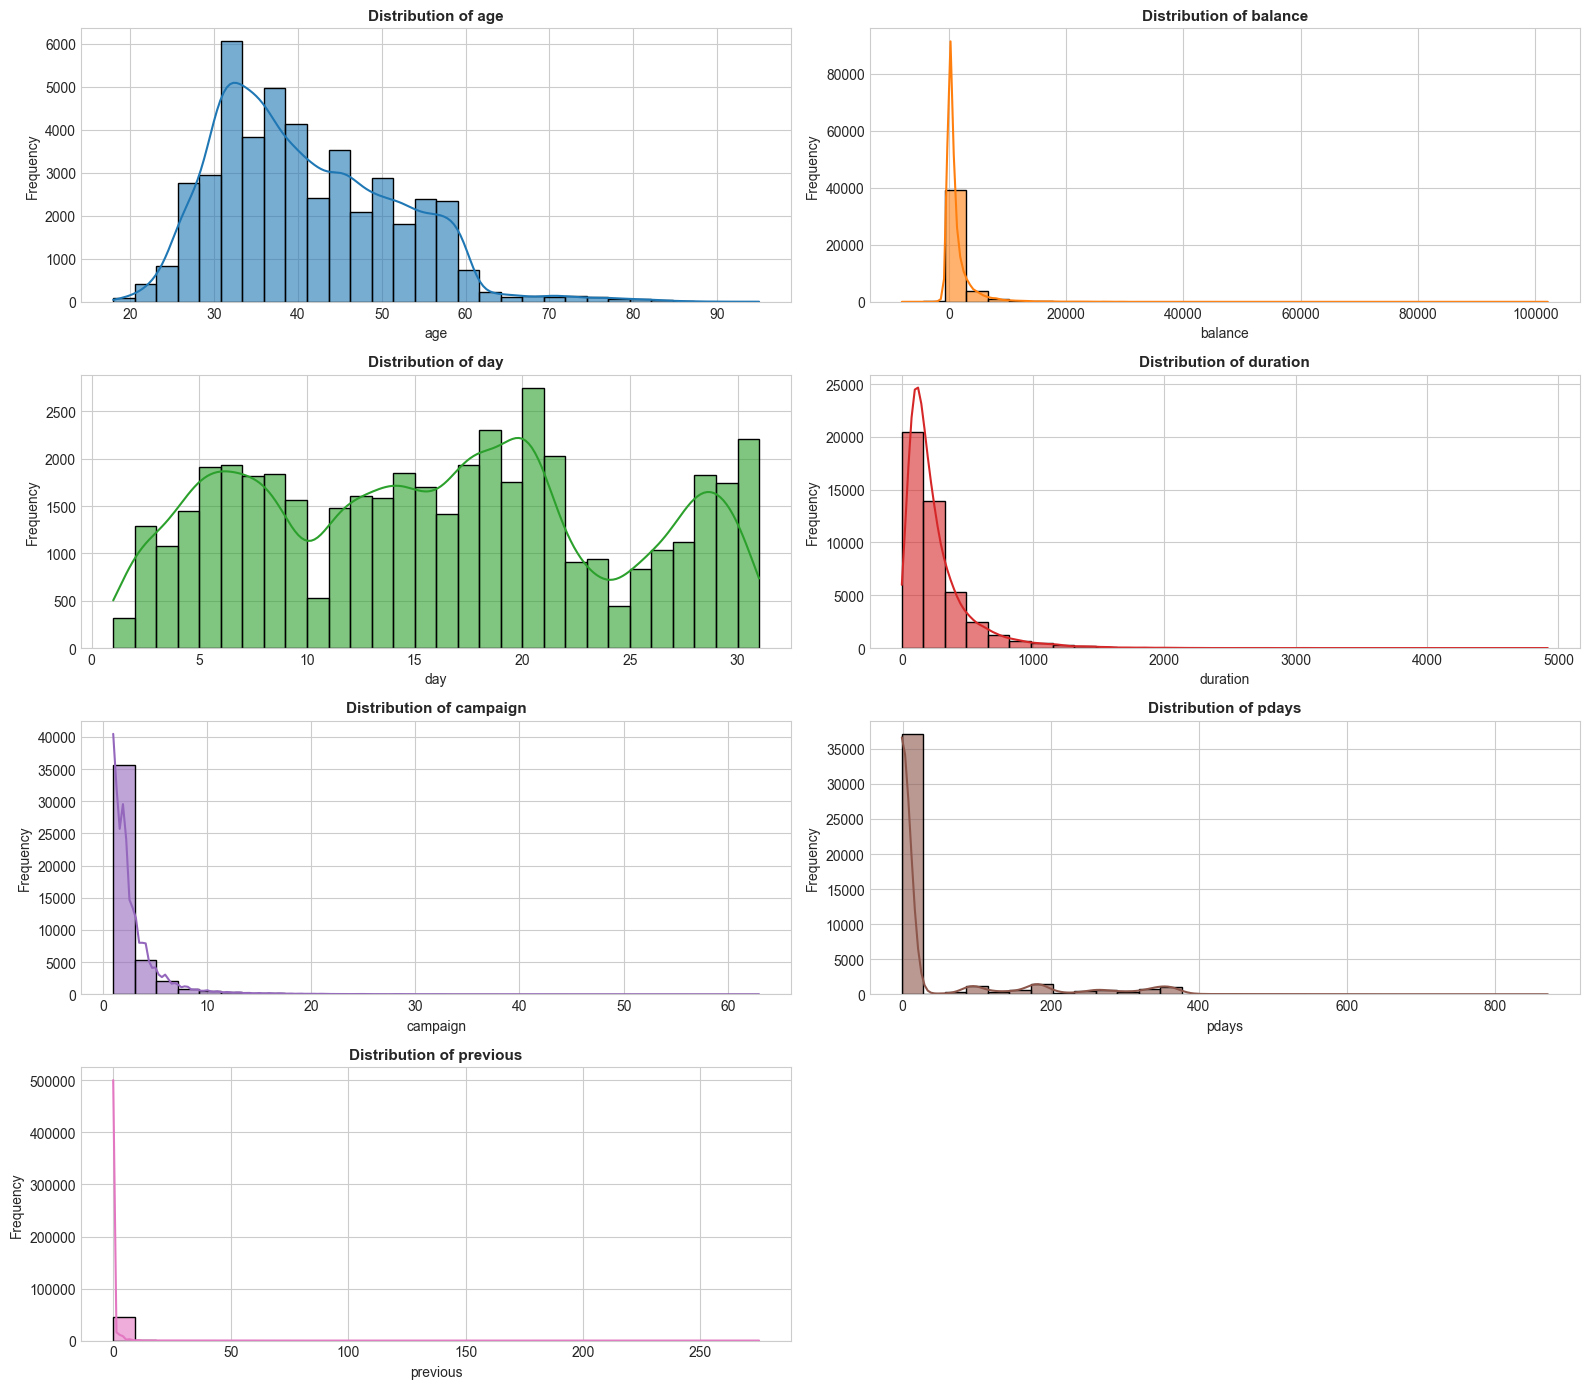

In [7]:
fig, axes = plt.subplots(4, 2, figsize=(16, 14))
axes = axes.flatten()

for idx, col in enumerate(num_cols):
    ax = axes[idx]
    sns.histplot(df[col], kde=True, ax=ax, color=palette[idx % len(palette)], bins=30, alpha=0.6)
    ax.set_title(f'Distribution of {col}', fontsize=11, fontweight='bold')
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel('Frequency', fontsize=10)

# Hide unused subplot
axes[-1].axis('off')
plt.tight_layout()
plt.show()

**Observation**:
1. `age` ranges from 18 to 95 with an approximately normal, slightly right-skewed distribution peaking between 30 and 40 years.
2. `balance` (average yearly bank balance in euros) exhibits extreme positive skewness, with values spanning from -8,019 euros to +102,127 euros, with the vast majority concentrated between 0 and 2,000 euros.
3. `day` (last contact day of month) is spread fairly evenly between 1 and 31, with minor dips at month ends.
4. `duration` (last contact duration in seconds) is heavily right-skewed, ranging from 0 to 4,918 seconds (~82 minutes), with a median of 180 seconds (3 minutes).
5. `campaign` (contacts performed during this campaign) has a median of 2, with rare extremes up to 63 contacts.
6. `pdays` (days since previous campaign contact) has a massive spike at -1 (36,954 clients, or 81.7%), signifying clients who were never previously contacted.
7. `previous` (number of contacts before this campaign) is 0 for the overwhelming majority of clients.

**ML Implication**:
- Features operate on vastly disparate scales (e.g., `balance` in thousands vs. `campaign` in single digits). Standardization (`StandardScaler`) is strictly necessary for distance-based and margin-based algorithms (KNN, SVC, Logistic Regression).
- The heavy concentration of `pdays == -1` justifies engineering a binary indicator feature (`pdays_contacted`) to represent whether prior campaign contact occurred.

#### 5.2 Categorical Predictor Feature Distributions
We visualize the empirical distribution of all 9 categorical predictor features.

C:\Users\naren\AppData\Local\Temp\ipykernel_568\3027390162.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, ax=ax, palette='Blues_r')
C:\Users\naren\AppData\Local\Temp\ipykernel_568\3027390162.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right', fontsize=9)
C:\Users\naren\AppData\Local\Temp\ipykernel_568\3027390162.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, ax=ax, palette='Blues_r')
C:\Users\naren\AppData\Local\Temp\ipykernel_568\3027390162.py:11: UserWarning: set_t

C:\Users\naren\AppData\Local\Temp\ipykernel_568\3027390162.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right', fontsize=9)
C:\Users\naren\AppData\Local\Temp\ipykernel_568\3027390162.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, ax=ax, palette='Blues_r')
C:\Users\naren\AppData\Local\Temp\ipykernel_568\3027390162.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right', fontsize=9)


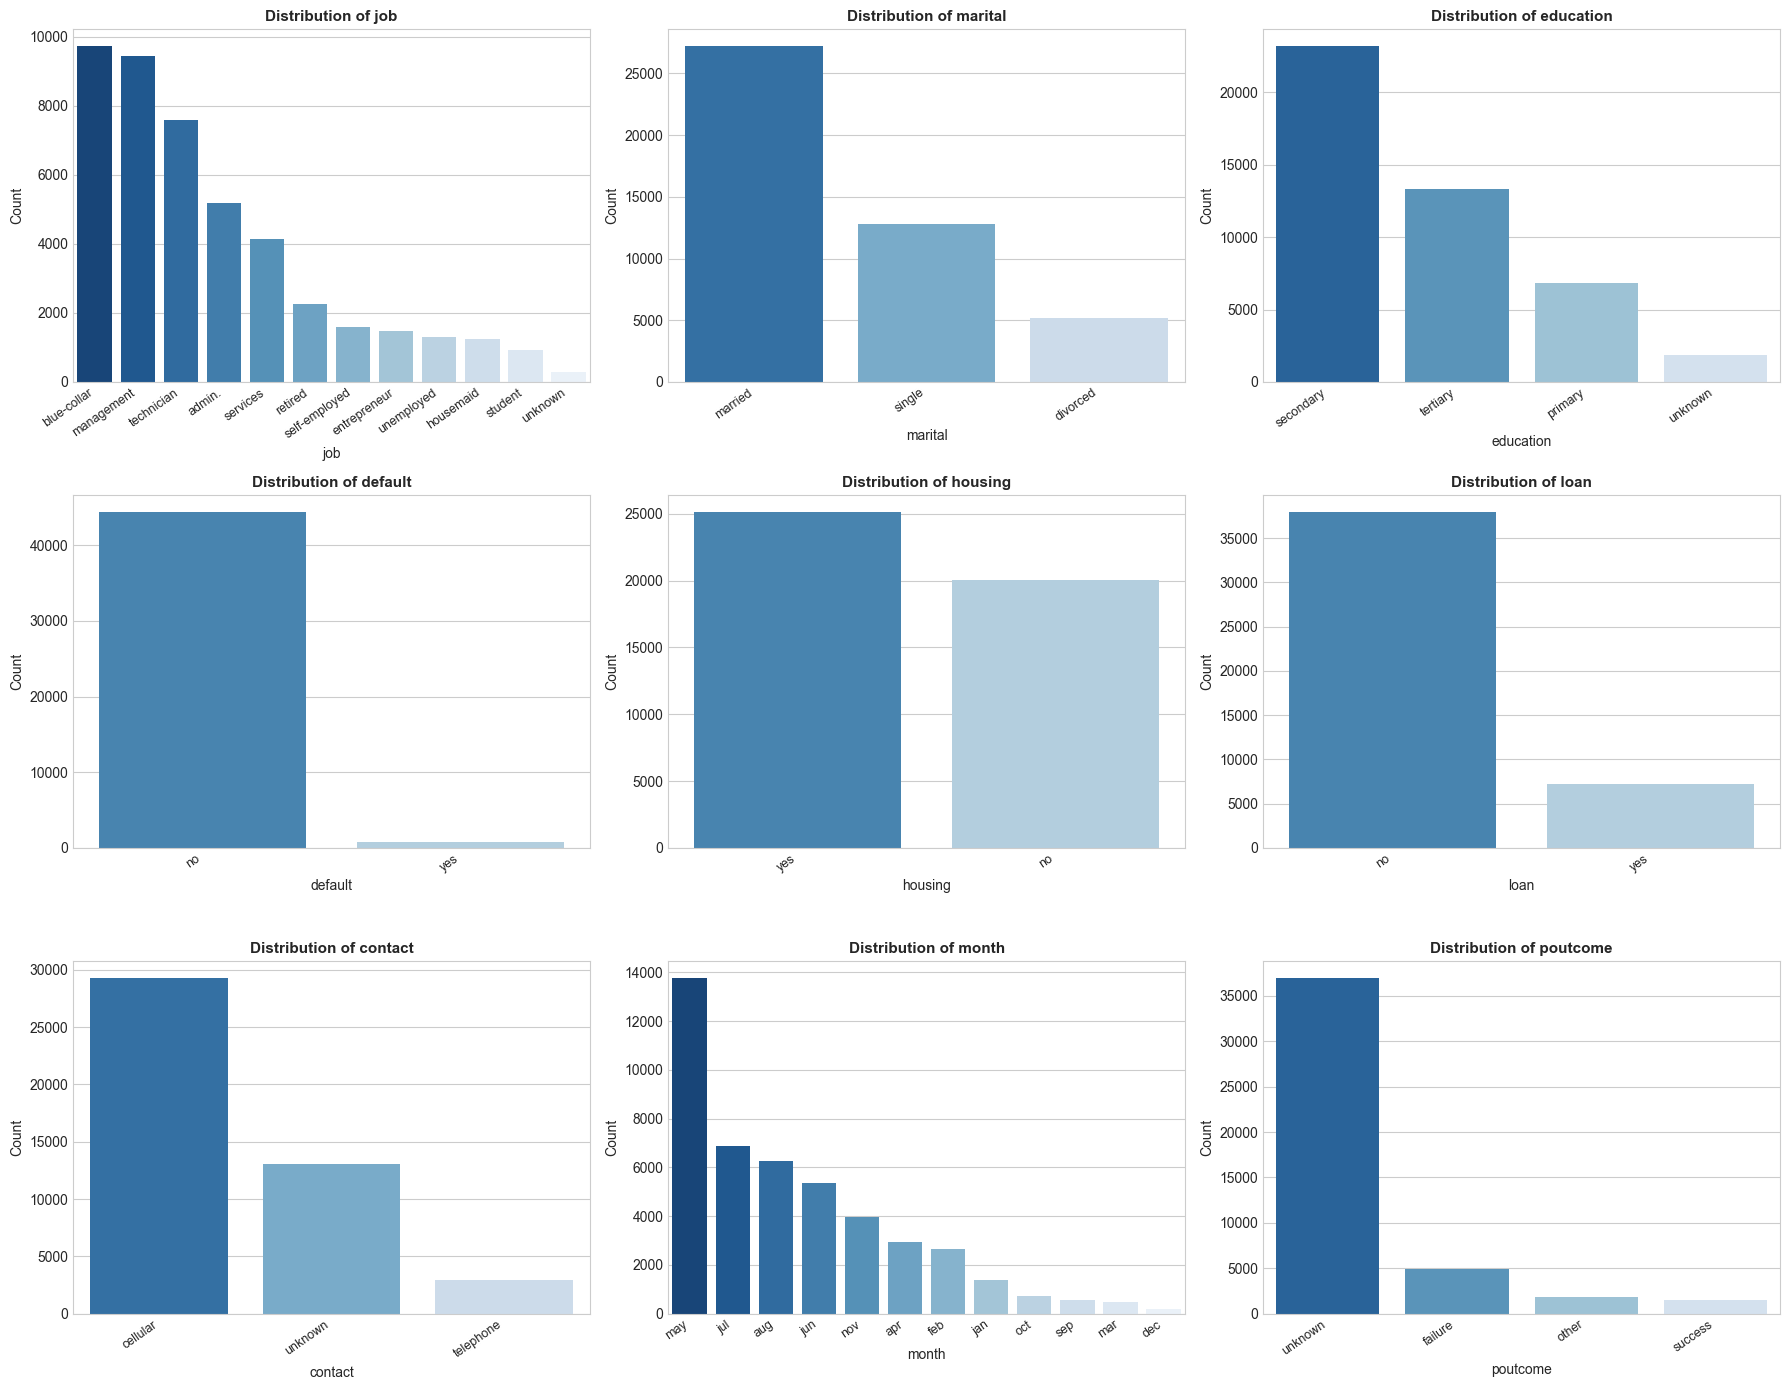

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for idx, col in enumerate(cat_cols):
    ax = axes[idx]
    counts = df[col].value_counts()
    sns.barplot(x=counts.index, y=counts.values, ax=ax, palette='Blues_r')
    ax.set_title(f'Distribution of {col}', fontsize=11, fontweight='bold')
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel('Count', fontsize=10)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right', fontsize=9)

plt.tight_layout()
plt.show()

**Observation**:
1. `job`: Management (9,458), blue-collar (9,732), and technician (7,597) represent the largest occupational cohorts.
2. `marital`: Married clients constitute the majority (27,214, or 60.2%), followed by single (12,790, or 28.3%) and divorced (5,207, or 11.5%).
3. `education`: Secondary education is predominant (23,202, or 51.3%), followed by tertiary (13,301, or 29.4%) and primary (6,851, or 15.2%).
4. `housing`: A slight majority of clients hold a housing loan (`yes`: 25,130, or 55.6%).
5. `loan`: Only a small minority hold a personal loan (`yes`: 7,244, or 16.0%).
6. `default`: Credit default is rare (`yes`: 815, or 1.8%).
7. `contact`: Cellular is the primary mode of contact (29,285, or 64.8%), while 13,020 contacts (28.8%) are unrecorded (`unknown`).
8. `month`: May accounts for the highest contact volume (13,766, or 30.4%), followed by July and August.
9. `poutcome`: The previous campaign outcome is `unknown` for 36,959 clients (81.7%), matching the non-contact rate in `pdays`.

**ML Implication**:
- High-cardinality features like `job` (12 levels) and `month` (12 levels) will expand dimensionality when one-hot encoded. We will use `OneHotEncoder(drop='first', sparse_output=False)` to prevent multicollinear dummy traps and ensure dense arrays compatible with `GaussianNB`.
- The category `'unknown'` represents missing contact metadata rather than random noise. Keeping `'unknown'` as an explicit categorical state allows algorithms to leverage the absence of contact history as an informative signal.

#### 5.3 Target Variable Distribution (`y`)
We plot the target class distribution to highlight the operational imbalance.

C:\Users\naren\AppData\Local\Temp\ipykernel_568\699408124.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, ax=ax, palette=colors)


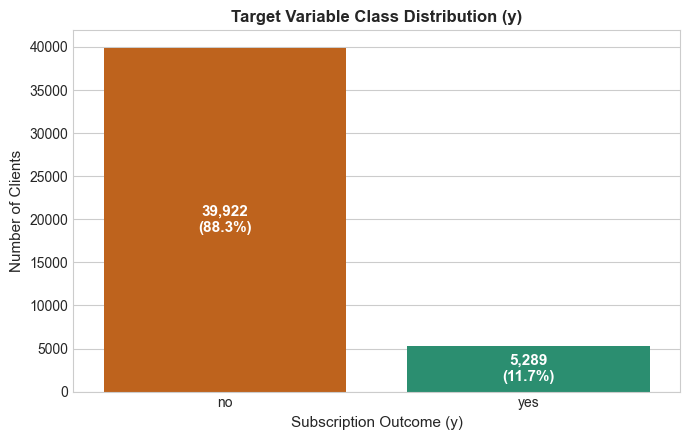

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = ['#d95f02', '#1b9e77']
sns.barplot(x=class_counts.index, y=class_counts.values, ax=ax, palette=colors)
ax.set_title('Target Variable Class Distribution (y)', fontsize=12, fontweight='bold')
ax.set_xlabel('Subscription Outcome (y)', fontsize=11)
ax.set_ylabel('Number of Clients', fontsize=11)

for idx, p in enumerate(ax.patches):
    height = p.get_height()
    pct = class_percentages.iloc[idx]
    ax.annotate(f'{int(height):,}\n({pct:.1f}%)',
                (p.get_x() + p.get_width() / 2., height / 2.),
                ha='center', va='center', fontsize=11, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

**Observation**:
The dataset displays an 88.3% to 11.7% class imbalance. The majority class (`'no'`) contains 39,922 records, while the positive class (`'yes'`) contains only 5,289 records.

**ML Implication**:
Standard accuracy is misleading in this context. A model predicting `'no'` universally achieves 88.3% accuracy while capturing 0 subscribers. Consequently:
- Stratified splitting (`stratify=y`) is essential to preserve class proportions.
- Evaluation must prioritize **Weighted F1-score, Positive-Class Recall, Positive-Class Precision, and ROC-AUC**.

#### 5.4 Pearson Correlation Heatmap of Numerical Features
We compute the pairwise linear correlation coefficients across all 7 numerical features and the binary target ($y = 1$ if 'yes', 0 if 'no').

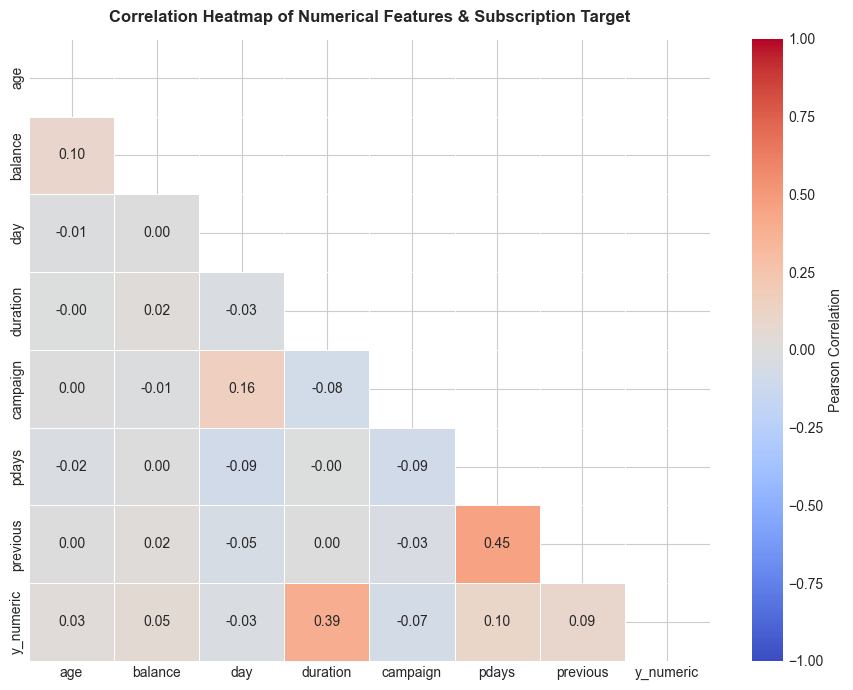

In [10]:
# Temporarily map target to binary for numerical correlation calculation
df_corr = df[num_cols].copy()
df_corr['y_numeric'] = (df['y'] == 'yes').astype(int)

plt.figure(figsize=(9, 7))
corr_matrix = df_corr.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix, 
    mask=mask, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation'}
)
plt.title('Correlation Heatmap of Numerical Features & Subscription Target', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

**Observation**:
1. `duration` exhibits the highest linear correlation with `y_numeric` ($r = +0.39$).
2. `pdays` and `previous` display moderate positive inter-correlation ($r = +0.45$), reflecting clients engaged in previous campaigns.
3. Most other numerical predictors demonstrate weak linear pairwise correlation ($|r| < 0.10$).

**ML Implication**:
Multicollinearity among numerical features is low. However, the moderate correlation of `duration` with the target highlights its strong predictive influence, which requires careful analytical and operational discussion.

#### 5.5 Feature-vs-Target Relationship Visualizations
We investigate three key feature-target relationships: Call Duration, Previous Campaign Outcome, and Age Distribution by Subscription Class.

C:\Users\naren\AppData\Local\Temp\ipykernel_568\1506783520.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\naren\AppData\Local\Temp\ipykernel_568\1506783520.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=poutcome_rates.index, y=poutcome_rates.values, ax=axes[1], palette='Greens_r')


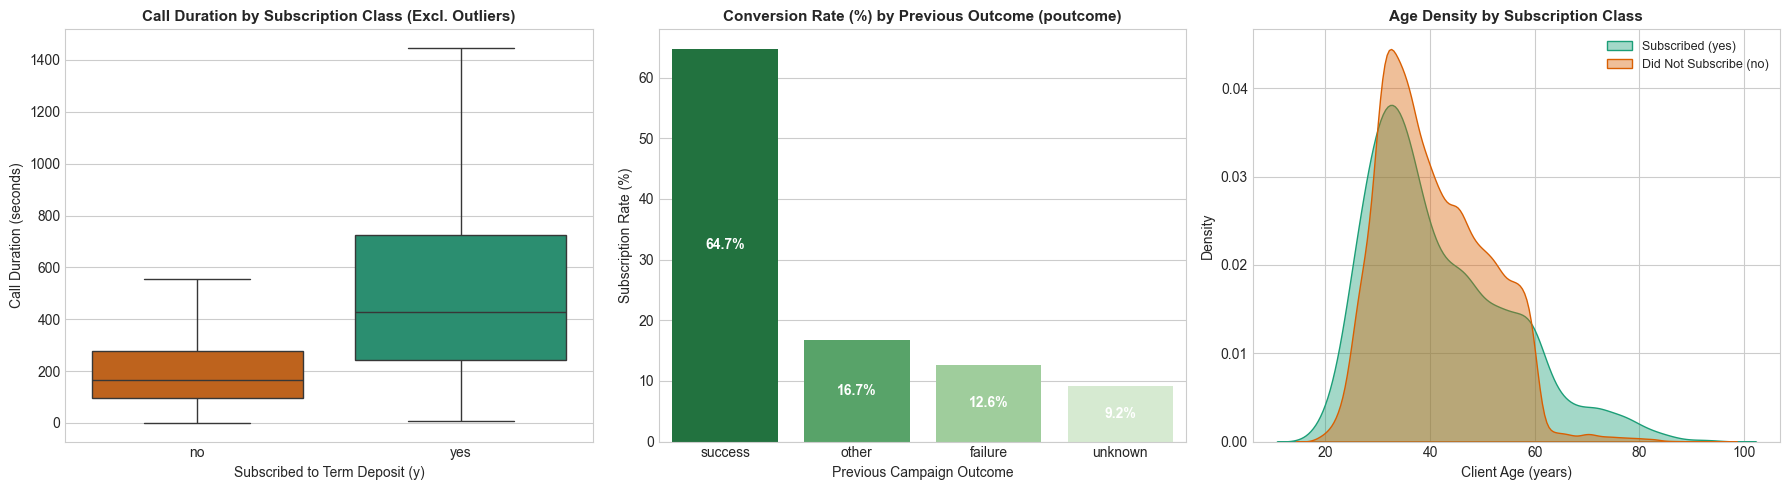

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Call Duration by Target Class (Log scale due to right skew)
sns.boxplot(
    data=df, x='y', y='duration', ax=axes[0], palette=['#d95f02', '#1b9e77'],
    showfliers=False
)
axes[0].set_title('Call Duration by Subscription Class (Excl. Outliers)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Subscribed to Term Deposit (y)', fontsize=10)
axes[0].set_ylabel('Call Duration (seconds)', fontsize=10)

# Plot 2: Previous Campaign Outcome (poutcome) vs Subscription Rate
poutcome_rates = df.groupby('poutcome')['y'].apply(lambda s: (s == 'yes').mean() * 100).sort_values(ascending=False)
sns.barplot(x=poutcome_rates.index, y=poutcome_rates.values, ax=axes[1], palette='Greens_r')
axes[1].set_title('Conversion Rate (%) by Previous Outcome (poutcome)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Previous Campaign Outcome', fontsize=10)
axes[1].set_ylabel('Subscription Rate (%)', fontsize=10)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}%",
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2.),
                     ha='center', va='center', fontsize=10, color='white', fontweight='bold')

# Plot 3: Age Distribution by Subscription Class
sns.kdeplot(data=df[df['y'] == 'yes']['age'], label='Subscribed (yes)', ax=axes[2], color='#1b9e77', fill=True, alpha=0.4)
sns.kdeplot(data=df[df['y'] == 'no']['age'], label='Did Not Subscribe (no)', ax=axes[2], color='#d95f02', fill=True, alpha=0.4)
axes[2].set_title('Age Density by Subscription Class', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Client Age (years)', fontsize=10)
axes[2].set_ylabel('Density', fontsize=10)
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

**Observation**:
1. **Call Duration**: Clients who subscribed had a median call duration of **426 seconds (~7.1 minutes)**, compared to **164 seconds (~2.7 minutes)** for non-subscribers.
2. **Previous Campaign Outcome (`poutcome`)**: Clients whose previous marketing contact was classified as `'success'` attained a **64.7% subscription rate**, compared to 12.6% for `'failure'`, 16.7% for `'other'`, and only 9.2% for `'unknown'`.
3. **Age Profile**: Younger clients (< 30) and senior clients (> 60) exhibit higher proportional subscription likelihood than mid-career clients (35–50).

**ML Implication**:
- Prior campaign success is an exceptionally powerful conversion signal.
- The strong association between call duration and subscription confirms its predictive power, but leads directly to a crucial real-world operational distinction.

### 6. Data Cleaning & Operational Feature Limitations

#### Data Cleaning Audit
1. **Missing Values**: 0 missing entries confirmed across all 17 features.
2. **Duplicates**: 0 duplicate rows confirmed.
3. **'Unknown' Categorical Levels**: Treated as explicit categories to preserve informative non-response signals.
4. **Class Imbalance Strategy**: In strict accordance with the prompt guidelines, we do **not** apply synthetic oversampling (e.g., SMOTE) or undersampling for Review 1. Keeping empirical class distributions intact ensures defensible, leak-free evaluations and true probability calibrations.

#### Critical Operational Limitation: Call `duration` Feature
> [!WARNING]
> **Operational Real-World Limitation of `duration`**:
> While `duration` is strongly predictive ($r = +0.39$, median call length 426s vs. 164s), **call duration is completely unknown before a telemarketing call is initiated**. A bank cannot know how long a phone call will last prior to dialing. Consequently, a model relying heavily on `duration` cannot be used for prospective lead scoring prior to placing calls; it only assesses conversion probability as or after a call concludes.
> Per project guidelines, `duration` is retained for Review 1 benchmark consistency, but this vital deployment limitation is explicitly noted.

In [12]:
# Summary of data cleaning audit
print("--- DATA CLEANING SUMMARY ---")
print(f"1. Total missing values: {df.isnull().sum().sum()}")
print(f"2. Total duplicate rows: {df.duplicated().sum()}")
print(f"3. Total observations retained: {len(df):,}")

--- DATA CLEANING SUMMARY ---
1. Total missing values: 0
2. Total duplicate rows: 0
3. Total observations retained: 45,211


### 7. Train/Test Split (Stratified 80:20)
To guarantee that both training and test partitions exhibit the exact same 88.3% / 11.7% class ratio, we partition the data using `stratify=y` with `test_size=0.20` and `random_state=42`.

In [13]:
from sklearn.model_selection import train_test_split

# Separate features and target
X_raw = df.drop(columns=['y']).copy()
y = (df['y'] == 'yes').astype(int)  # 1 = 'yes' (subscribed), 0 = 'no' (did not subscribe)

# Stratified 80:20 train/test split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set features shape: {X_train_raw.shape} | Labels shape: {y_train.shape}")
print(f"Test set features shape:     {X_test_raw.shape} | Labels shape: {y_test.shape}")

# Verify stratification exactness
strat_check = pd.DataFrame({
    'Partition': ['Full Dataset', 'Training Set', 'Held-out Test Set'],
    'Total Samples': [len(y), len(y_train), len(y_test)],
    'Subscribers (yes = 1)': [y.sum(), y_train.sum(), y_test.sum()],
    'Non-Subscribers (no = 0)': [(y == 0).sum(), (y_train == 0).sum(), (y_test == 0).sum()],
    'Subscription Rate (%)': [
        f"{(y.mean() * 100):.2f}%",
        f"{(y_train.mean() * 100):.2f}%",
        f"{(y_test.mean() * 100):.2f}%"
    ]
})
display(strat_check)

Training set features shape: (36168, 16) | Labels shape: (36168,)
Test set features shape:     (9043, 16) | Labels shape: (9043,)


,Partition,Total Samples,Subscribers (yes = 1),Non-Subscribers (no = 0),Subscription Rate (%)
0,Full Dataset,45211,5289,39922,11.70%
1,Training Set,36168,4231,31937,11.70%
2,Held-out Test Set,9043,1058,7985,11.70%


### 8. Feature Engineering
We engineer domain-justified features:
1. **`pdays_contacted`**:
   - **Construction**: Binary flag where `pdays_contacted = 1` if `pdays != -1`, and `0` if `pdays == -1`.
   - **Rationale**: 81.7% of clients have `pdays == -1` (never previously contacted). Transforming this spike into an explicit indicator allows linear and margin-based models to capture prior marketing familiarity without distorting continuous distance metrics.
   - **Limitations**: Does not distinguish between clients contacted 10 days ago vs. 300 days ago (the continuous `pdays` feature is retained alongside it).
2. **`balance_negative`**:
   - **Construction**: Binary flag where `balance_negative = 1` if `balance < 0`, and `0` otherwise.
   - **Rationale**: Overdrawn accounts represent liquidity-constrained clients who are financially incapable of committing funds to a long-term term deposit.
   - **Zero Leakage**: Features are constructed purely using row-level attributes of each individual observation.

In [14]:
def engineer_classification_features(data):
    df_out = data.copy()
    
    # 1. Prior campaign contact indicator
    df_out['pdays_contacted'] = (df_out['pdays'] != -1).astype(int)
    
    # 2. Negative bank balance indicator
    df_out['balance_negative'] = (df_out['balance'] < 0).astype(int)
    
    return df_out

X_train_fe = engineer_classification_features(X_train_raw)
X_test_fe = engineer_classification_features(X_test_raw)

print(f"Feature engineering complete.")
print(f"Engineered training shape: {X_train_fe.shape} | Test shape: {X_test_fe.shape}")
X_train_fe[['pdays', 'pdays_contacted', 'balance', 'balance_negative']].head(4)

Feature engineering complete.
Engineered training shape: (36168, 18) | Test shape: (9043, 18)


,pdays,pdays_contacted,balance,balance_negative
24001,-1,0,861,0
43409,185,1,4126,0
20669,-1,0,244,0
18810,-1,0,0,0


### 9. Encoding and Preprocessing Pipeline
We construct a scikit-learn `ColumnTransformer`:
- **Continuous Numerical Features**: Standardized using `StandardScaler()`.
- **Categorical Features**: Encoded using `OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)`.

> [!IMPORTANT]
> **Dense Output for GaussianNB**:
> By specifying `sparse_output=False`, the preprocessor outputs a dense NumPy array directly. This guarantees full compatibility with `GaussianNB` (which does not accept sparse matrix inputs) and ensures seamless execution across all five classification algorithms.

> [!CAUTION]
> **Strict Leakage Prevention**:
> The `ColumnTransformer` is fitted **strictly on `X_train_fe`**. The fitted preprocessor is then used to transform both `X_train_fe` and `X_test_fe`.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

categorical_cols_model = X_train_fe.select_dtypes(include=['object']).columns.tolist()
numerical_cols_model = [c for c in X_train_fe.columns if c not in categorical_cols_model]

preprocessor_cls = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols_model),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_cols_model)
    ]
)

# Fit strictly on training data
X_train_prep = preprocessor_cls.fit_transform(X_train_fe)
X_test_prep = preprocessor_cls.transform(X_test_fe)

# Retrieve transformed feature names
cat_encoder_cls = preprocessor_cls.named_transformers_['cat']
cat_names_cls = cat_encoder_cls.get_feature_names_out(categorical_cols_model).tolist()
all_features_cls = numerical_cols_model + cat_names_cls

print(f"Preprocessing complete. Total feature dimensionality: {X_train_prep.shape[1]}")
print(f"Is output matrix dense: {isinstance(X_train_prep, np.ndarray)}")
print(f"Transformed training matrix shape: {X_train_prep.shape}")
print(f"Transformed test matrix shape:     {X_test_prep.shape}")

Preprocessing complete. Total feature dimensionality: 44
Is output matrix dense: True
Transformed training matrix shape: (36168, 44)
Transformed test matrix shape:     (9043, 44)
